# Risk set of a two-group linear regression (Figure 4)

Example of Appendix F.3: $\Theta = \{\theta : \|\theta\| \le 1\}$, $\beta_1 = (0.4, 0)$, $\beta_2 = (0.4, 0.6)$, $\Sigma_1 = \begin{pmatrix} 1 & 0.5 \\ 0.5 & 1 \end{pmatrix}$, $\Sigma_2 = I$, $\sigma_g = 1$.

Left: the risk set and its convex hull. Right: its comprehensive closure. Writes `convex_hull_bargaining.pdf` to this directory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Two-group linear regression example (Appendix F.3)
Sigma1 = np.array([[1,0.5],[0.5,1]])
Sigma2 = np.array([[1,0.],[0,1]])
beta1 = [0.4, 0]
beta2 = [0.4, 0.6]

print("Sigma1:")
print(Sigma1)
print("\nSigma2:")
print(Sigma2)
print("\nbeta1:", beta1)
print("beta2:", beta2)


# Create a grid of theta values and filter by circle constraint
theta1 = np.linspace(-1, 1, 1000)
theta2 = np.linspace(-1, 1, 1000)
Theta1, Theta2 = np.meshgrid(theta1, theta2)

# Filter to only include points within the unit disk theta_1^2 + theta_2^2 <= 1
mask = (Theta1**2 + Theta2**2) <= 1

# Extract theta values within the circle
Theta1_circle = Theta1[mask]
Theta2_circle = Theta2[mask]

print(f"Number of theta points in circle: {len(Theta1_circle)}")

# Risk of each theta: (theta - beta_g)^T Sigma_g (theta - beta_g) + sigma_g^2 with sigma_g = 1
X_circle = []
Y_circle = []

for i in range(len(Theta1_circle)):
    theta = np.array([Theta1_circle[i], Theta2_circle[i]])
    
    # Compute (theta - beta1)^T Sigma1 (theta - beta1)
    diff1 = theta - beta1
    x_val = diff1 @ Sigma1 @ diff1 + 1
    
    # Compute (theta - beta2)^T Sigma2 (theta - beta2)
    diff2 = theta - beta2
    y_val = diff2 @ Sigma2 @ diff2 + 1
    
    X_circle.append(x_val)
    Y_circle.append(y_val)

X_circle = np.array(X_circle)
Y_circle = np.array(Y_circle)


Sigma1:
[[1.  0.5]
 [0.5 1. ]]

Sigma2:
[[1. 0.]
 [0. 1.]]

beta1: [0.4, 0]
beta2: [0.4, 0.6]
Number of theta points in circle: 783764


Original set size: 783764
Number of vertices on convex hull: 958


/var/folders/kp/c5r14smx5gj41nmfg_mpskw80000gr/T/ipykernel_69481/3437308546.py:78: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  hull_polygon = Polygon(points[hull.vertices], alpha=0.4, color='blue',


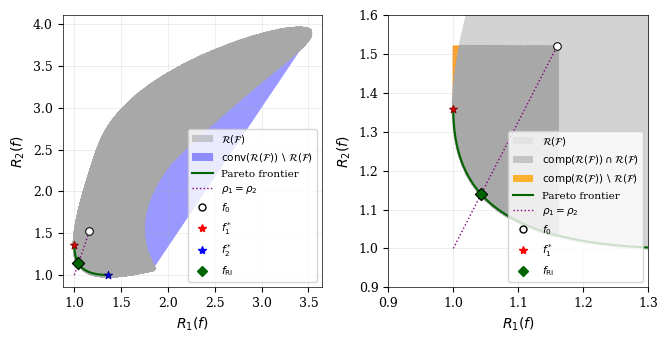

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

# Set ICML style parameters
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9, 'figure.titlesize': 9,
    'lines.linewidth': 0.75, 'lines.markersize': 4, 'axes.linewidth': 0.5,
    'grid.linewidth': 0.5, 'grid.alpha': 0.3,
})

# Stack the points
points = np.column_stack([X_circle, Y_circle])
print(f"Original set size: {len(points)}")

# Convex hull
hull = ConvexHull(points)
print(f"Number of vertices on convex hull: {len(hull.vertices)}")

# Pareto frontier
hull_points = points[hull.vertices]
sorted_idx = np.argsort(hull_points[:, 0])
hull_sorted = hull_points[sorted_idx]

pareto_frontier = [hull_sorted[0]]
for point in hull_sorted[1:]:
    if point[1] <= pareto_frontier[-1][1]:
        pareto_frontier.append(point)
pareto_frontier = np.array(pareto_frontier)

# Baseline and ideal points
theta0 = np.array([0,0])
diff1 = theta0 - beta1
r0_1 = diff1 @ Sigma1 @ diff1 + 1
diff2 = theta0 - beta2
r0_2 = diff2 @ Sigma2 @ diff2 + 1
r1_star = X_circle.min()
r2_star = Y_circle.min()

# Equal relative improvement line
def equal_rho_line(R1):
    return r0_2 - (r0_2 - r2_star) * (r0_1 - R1) / (r0_1 - r1_star)

# Find KS solution
def dist_to_equal_rho(point):
    R1, R2 = point
    rho1 = (r0_1 - R1) / (r0_1 - r1_star)
    rho2 = (r0_2 - R2) / (r0_2 - r2_star)
    return (rho1 - rho2)**2

ks_idx = np.argmin([dist_to_equal_rho(p) for p in pareto_frontier])
ks_point = pareto_frontier[ks_idx]

# Comprehensive closure boundary (bounded by f_0)
comp_r1_values = np.linspace(pareto_frontier[:, 0].min(), r0_1, 200)
comp_r2_values = []

for r1 in comp_r1_values:
    valid_points = pareto_frontier[pareto_frontier[:, 0] <= r1]
    if len(valid_points) > 0:
        min_r2 = valid_points[:, 1].min()
        comp_r2_values.append(min_r2)
    else:
        comp_r2_values.append(r0_2)

comp_r2_values = np.array(comp_r2_values)

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.75, 3.5))

# ===== LEFT PLOT: Risk set + Convex hull =====
# Convex hull of the risk set
from matplotlib.patches import Polygon, Patch
from matplotlib.lines import Line2D

hull_polygon = Polygon(points[hull.vertices], alpha=0.4, color='blue', 
                      edgecolor='none', linewidth=0, zorder=1)
ax1.add_patch(hull_polygon)

# R(F) - the actual risk set
ax1.scatter(X_circle, Y_circle, c='darkgray', alpha=0.6, s=1.5, 
           rasterized=True, zorder=2)

# Pareto frontier
ax1.plot(pareto_frontier[:, 0], pareto_frontier[:, 1], 'darkgreen', 
         linewidth=1.5, zorder=4)

# Equal relative improvement line
r1_line = np.linspace(r1_star, r0_1, 100)
r2_line = equal_rho_line(r1_line)
ax1.plot(r1_line, r2_line, color='purple', linewidth=1, linestyle=':', zorder=3)

# Key points
ax1.scatter(r0_1, r0_2, c='white', s=30, marker='o', edgecolors='black', 
           linewidths=0.75, zorder=5)
ax1.scatter(r1_star, Y_circle[np.argmin(X_circle)], c='red', s=35, marker='*', 
           edgecolors='darkred', linewidths=0.75, zorder=5)
ax1.scatter(X_circle[np.argmin(Y_circle)], r2_star, c='blue', s=35, marker='*', 
           edgecolors='darkblue', linewidths=0.75, zorder=5)
ax1.scatter(ks_point[0], ks_point[1], c='darkgreen', s=40, marker='D', 
           edgecolors='black', linewidths=0.75, zorder=6)

# Custom legend
legend_elements = [
    Patch(facecolor='darkgray', alpha=0.6, label='$\\mathcal{R}(\\mathcal{F})$'),
    Patch(facecolor='blue', alpha=0.4, label='$\\mathrm{conv}(\\mathcal{R}(\\mathcal{F})) \\setminus \\mathcal{R}(\\mathcal{F})$'),
    Line2D([0], [0], color='darkgreen', linewidth=1.5, label='Pareto frontier'),
    Line2D([0], [0], color='purple', linewidth=1, linestyle=':', label='$\\rho_1 = \\rho_2$'),
    Line2D([0], [0], color='white', marker='o', linestyle='None', 
           markerfacecolor='white', markeredgecolor='black', markersize=5, label='$f_0$'),
    Line2D([0], [0], color='red', marker='*', linestyle='None', 
           markersize=6, label='$f_1^*$'),
    Line2D([0], [0], color='blue', marker='*', linestyle='None', 
           markersize=6, label='$f_2^*$'),
    Line2D([0], [0], color='darkgreen', marker='D', linestyle='None', 
           markersize=5, label='$f_{\\mathrm{RI}}$')
]

ax1.set_xlabel('$R_1(f)$')
ax1.set_ylabel('$R_2(f)$')
ax1.grid(True, alpha=0.3)
ax1.legend(handles=legend_elements, loc='lower right', fontsize=7.5)

# ===== RIGHT PLOT: Risk set + Comprehensive closure =====
# Filter comp_r1_values and comp_r2_values to only include points <= (r0_1, r0_2)
mask = (comp_r1_values <= r0_1) & (comp_r2_values <= r0_2)
comp_r1_filtered = comp_r1_values[mask]
comp_r2_filtered = comp_r2_values[mask]

# Add the boundary segments to close the region
right_boundary_r1 = np.array([r0_1, r0_1])
right_boundary_r2 = np.array([comp_r2_filtered[-1], r0_2])
top_boundary_r1 = np.array([comp_r1_filtered[0], r0_1])
top_boundary_r2 = np.array([r0_2, r0_2])

# Combine all boundaries for fill
all_r1 = np.concatenate([comp_r1_filtered, right_boundary_r1, top_boundary_r1[::-1]])
all_r2 = np.concatenate([comp_r2_filtered, right_boundary_r2, top_boundary_r2[::-1]])

# Fill the comprehensive closure region (bounded by f_0)
ax2.fill(all_r1, all_r2, alpha=0.8, color='darkorange', rasterized=True, zorder=1)

# Separate R(F) into two parts: inside and outside comp(R(F))
# comp(R(F)) ∩ R(F): points in R(F) that are <= (r0_1, r0_2)
mask_inside = (X_circle <= r0_1) & (Y_circle <= r0_2)
# R(F) \ comp(R(F)): points in R(F) that are outside
mask_outside = ~mask_inside

# Plot R(F) ∩ comp(R(F)) in darkgray (same as left plot)
ax2.scatter(X_circle[mask_inside], Y_circle[mask_inside], c='darkgray', 
           alpha=0.6, s=1.5, rasterized=True, zorder=3)

# Plot R(F) \ comp(R(F)) in light gray
ax2.scatter(X_circle[mask_outside], Y_circle[mask_outside], c='lightgray', 
           alpha=0.4, s=1.5, rasterized=True, zorder=2)

# Pareto frontier
ax2.plot(pareto_frontier[:, 0], pareto_frontier[:, 1], 'darkgreen', 
         linewidth=1.5, zorder=4)

# Equal relative improvement line
ax2.plot(r1_line, r2_line, color='purple', linewidth=1, linestyle=':', zorder=3)

# Key points
ax2.scatter(r0_1, r0_2, c='white', s=30, marker='o', edgecolors='black', 
           linewidths=0.75, zorder=5)
ax2.scatter(r1_star, Y_circle[np.argmin(X_circle)], c='red', s=35, marker='*', 
           edgecolors='darkred', linewidths=0.75, zorder=5)
ax2.scatter(X_circle[np.argmin(Y_circle)], r2_star, c='blue', s=35, marker='*', 
           edgecolors='darkblue', linewidths=0.75, zorder=5)
ax2.scatter(ks_point[0], ks_point[1], c='darkgreen', s=40, marker='D', 
           edgecolors='black', linewidths=0.75, zorder=6)

# Custom legend for right plot
legend_elements_2 = [
    Patch(facecolor='lightgray', alpha=0.4, label='$\\mathcal{R}(\\mathcal{F})$'),
    Patch(facecolor='darkgray', alpha=0.6, label='$\\mathrm{comp}(\\mathcal{R}(\\mathcal{F})) \\cap \\mathcal{R}(\\mathcal{F})$'),
    Patch(facecolor='orange', alpha=0.8, label='$\\mathrm{comp}(\\mathcal{R}(\\mathcal{F})) \\setminus \\mathcal{R}(\\mathcal{F})$'),
    Line2D([0], [0], color='darkgreen', linewidth=1.5, label='Pareto frontier'),
    Line2D([0], [0], color='purple', linewidth=1, linestyle=':', label='$\\rho_1 = \\rho_2$'),
    Line2D([0], [0], color='white', marker='o', linestyle='None', 
           markerfacecolor='white', markeredgecolor='black', markersize=5, label='$f_0$'),
    Line2D([0], [0], color='red', marker='*', linestyle='None', 
           markersize=6, label='$f_1^*$'),
    Line2D([0], [0], color='darkgreen', marker='D', linestyle='None', 
           markersize=5, label='$f_{\\mathrm{RI}}$')
]

ax2.set_xlabel('$R_1(f)$')
ax2.set_ylabel('$R_2(f)$')
ax2.grid(True, alpha=0.3)
ax2.legend(handles=legend_elements_2, loc='lower right', fontsize=7.5)
ax2.set_xlim([0.9, 1.3])
ax2.set_ylim([0.9, 1.6])

plt.tight_layout()
plt.savefig('convex_hull_bargaining.pdf', dpi=300, bbox_inches='tight')
plt.show()